# Lab 8


## Setup for SUSY Dataset

Use the SUSY dataset for the rest of this lab. Here is a basic setup. It reads the full file you downloaded in Lab 7 (5 million rows, about 760 MB in memory once loaded). If your computer struggles, read `../Lab.7/SUSY-small.csv` instead (the first 500,000 rows) and divide the sample sizes below by ten.

`RawNames` are the 8 quantities measured directly; `FeatureNames` are the 10 derived from them, which the physicists designed to separate signal from background. You will need both in Exercise 3.

In [31]:
# Our usual libraries...
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from IPython.display import HTML, display
import tabulate

In [32]:
filename="../Lab.7/SUSY.csv"
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", 
          "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET",
          "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=[v for v in VarNames[1:] if v not in RawNames]
df = pd.read_csv(filename, dtype='float64', names=VarNames)

## Scikit-Learn

[Scikit-learn](https://scikit-learn.org) is a rich python library for data science, including machine learning. For example, we can build a Fisher Discriminant (aka Linear Discriminant Analysis, or LDA). 

### Exercise 1: Install Scikit-Learn

`scikit-learn` is in the course `requirements.txt`, so it should already be in your environment: check that `import sklearn` works. If it doesn't, follow the [Installation Instructions](https://scikit-learn.org/stable/install.html).

In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from IPython.display import HTML, display
import tabulate

In [34]:
filename="../Lab.7/SUSY.csv"
VarNames=["signal", "l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta",
          "l_2_phi", "MET", "MET_phi", "MET_rel", "axial_MET",
          "M_R", "M_TR_2", "R", "MT2", "S_R", "M_Delta_R", "dPhi_r_b", "cos_theta_r1"]
RawNames=["l_1_pT", "l_1_eta","l_1_phi", "l_2_pT", "l_2_eta", "l_2_phi", "MET", "MET_phi"]
FeatureNames=[v for v in VarNames[1:] if v not in RawNames]
df = pd.read_csv(filename, dtype='float64', names=VarNames)

In [35]:
import sklearn
print(sklearn.__version__)

1.6.1


### Exercise 2: Read About Classifiers

#### Part a
Scikit-learn offers an impressively comprehensive list of machine learning algorithms. Browse through [scikit-learn's documentation](https://scikit-learn.org/stable/index.html). You'll note the algorithms are organized into classification, regression, clustering, dimensionality reduction, model selection, and preprocessing. Browse through the list of [classification algorithms](https://scikit-learn.org/stable/supervised_learning.html#supervised-learning). 

#### Part b
Note scikit-learn's documentation is rather comprehensive. The documentation on [linear models](https://scikit-learn.org/stable/modules/linear_model.html) shows how classification problems are setup. Read about the first few methods and try to comprehend the example codes. Skim the rest of the document.

#### Part c
Read through the [LDA Documentation](https://scikit-learn.org/stable/modules/lda_qda.html).


### Exercise 3: Training a Classifier

Let's repeat what we did by hand in the previous lab (Lab 7, Exercise 8) using scikit-learn. We'll use an LDA classifier, which we can instantiate as follows:

In [36]:
import sklearn.discriminant_analysis as DA
Fisher=DA.LinearDiscriminantAnalysis()

As discussed in the lecture, to properly formulate our problem, we'll have to:

* Define the inputs (X) vs outputs (Y)
* Designate training vs testing samples (in order to get an unbiased assessment of the performance of machine learning algorithms)

For example, here we'll use 4M events for training and the remainder for testing.

In [37]:
N_Train=4000000

Train_Sample=df[:N_Train]
Test_Sample=df[N_Train:]

X_Train=Train_Sample[VarNames[1:]]
y_Train=Train_Sample["signal"]

X_Test=Test_Sample[VarNames[1:]]
y_Test=Test_Sample["signal"]

Test_sig=Test_Sample[Test_Sample.signal==1]
Test_bkg=Test_Sample[Test_Sample.signal==0]


We can train the classifier as follows:

In [38]:
Fisher.fit(X_Train,y_Train)

LinearDiscriminantAnalysis()

We can plot the output, comparing signal and background:

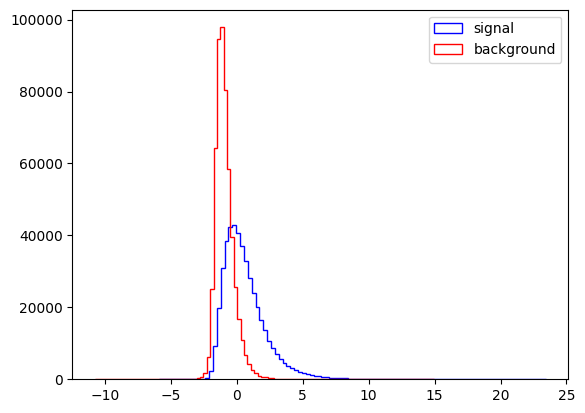

In [39]:
plt.figure()
plt.hist(Fisher.decision_function(Test_sig[VarNames[1:]]),bins=100,histtype="step", color="blue", label="signal",stacked=True)
plt.hist(Fisher.decision_function(Test_bkg[VarNames[1:]]),bins=100,histtype="step", color="red", label="background",stacked=True)
plt.legend(loc='upper right')
plt.show()

#### Part a

Compare the ROC curves computed on the test and on the training samples, in a single plot. Do you see a bias? (Use `Fisher.decision_function` on each sample, and `roc_curve` as in Exercise 5.)

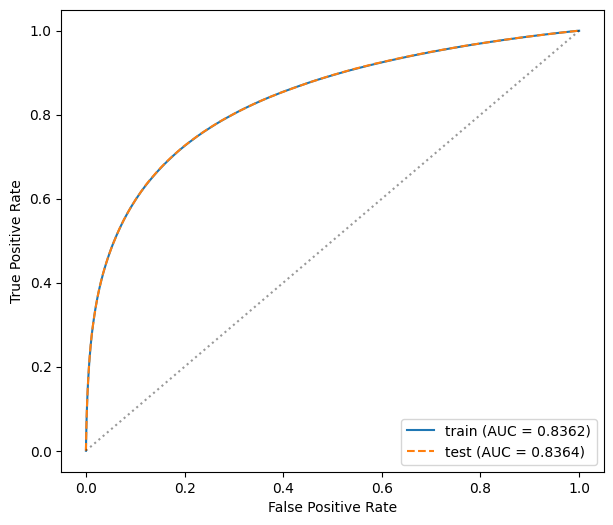

In [40]:
from sklearn.metrics import roc_curve, auc

fpr_tr, tpr_tr, _ = roc_curve(y_Train, Fisher.decision_function(X_Train))
fpr_te, tpr_te, _ = roc_curve(y_Test,  Fisher.decision_function(X_Test))

plt.figure(figsize=(7, 6))
plt.plot(fpr_tr, tpr_tr, label=f"train (AUC = {auc(fpr_tr, tpr_tr):.4f})")
plt.plot(fpr_te, tpr_te, "--", label=f"test (AUC = {auc(fpr_te, tpr_te):.4f})")
plt.plot([0, 1], [0, 1], "k:", alpha=0.4)
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.legend(loc="lower right"); plt.show()

#### Part b

Train three Fisher discriminants, using as input (1) only the raw quantities (`RawNames`), (2) only the derived features (`FeatureNames`), and (3) all 18. Compare their ROC curves, computed on the test sample, in a single plot. Which inputs carry the separation?

In [ ]:
feature_sets = {
    "Raw (8)":            RawNames,
    "Derived (10)":       FeatureNames,
    "Raw + Derived (18)": VarNames[1:],
}

plt.figure(figsize=(7, 6))
for name, feats in feature_sets.items():
    clf = DA.LinearDiscriminantAnalysis().fit(Train_Sample[feats], y_Train)
    fpr, tpr, _ = roc_curve(y_Test, clf.decision_function(Test_Sample[feats]))
    plt.plot(fpr, tpr, label=f"{name}, AUC = {auc(fpr, tpr):.4f}")
plt.plot([0, 1], [0, 1], "k:", alpha=0.4)
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("Fisher discriminant, test sample")
plt.legend(loc="lower right"); plt.show()

### Exercise 4: Comparing Techniques

#### Part a
Select 3 different classifiers from the techniques listed [here](https://scikit-learn.org/stable/supervised_learning.html#supervised-learning) to compare. Note that you can use the multi-layer perceptron to build a deep network, though training may be prohibitively slow. So avoid this technique.

#### Part b

Write a function that takes an instantiated classifier and performs the comparison from Exercise 3b. Use the function on each of the classifiers you chose in part a.

#### Part c

Use the best method from part b to compute the maximal significance $\sigma_S= \frac{N_S}{\sqrt{N_S+N_B}}$ for the four scenarios in Lab 7 (Exercise 5.3), choosing the cut on the classifier's output that maximizes it.

In [ ]:
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier

# Exercise 4a: 
classifiers = {
    "Logistic Regression":     (make_pipeline(StandardScaler(), LogisticRegression(max_iter=500)), 1_000_000),
    "Quadratic Discriminant":  (DA.QuadraticDiscriminantAnalysis(), N_Train),
    "Hist. Gradient Boosting": (HistGradientBoostingClassifier(max_iter=200), N_Train),
}

def score(clf, X):
    """Continuous classifier output, whichever method the classifier supports."""
    if hasattr(clf, "decision_function"):
        return clf.decision_function(X)
    return clf.predict_proba(X)[:, 1]

# Exercise 4b: 
def compare_feature_sets(clf, n_train, label=""):
    plt.figure(figsize=(7, 6))
    aucs, scores = {}, {}
    for name, feats in feature_sets.items():
        c = clone(clf).fit(Train_Sample[feats][:n_train], y_Train[:n_train])
        s = score(c, Test_Sample[feats])
        fpr, tpr, _ = roc_curve(y_Test, s)
        aucs[name], scores[name] = auc(fpr, tpr), s
        plt.plot(fpr, tpr, label=f"{name}, AUC = {aucs[name]:.4f}")
    plt.plot([0, 1], [0, 1], "k:", alpha=0.4)
    plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
    plt.title(f"{label} (test sample)"); plt.legend(loc="lower right"); plt.show()
    return aucs, scores

all_aucs, all_scores = {}, {}
for name, (clf, n) in classifiers.items():
    all_aucs[name], all_scores[name] = compare_feature_sets(clf, n, label=name)

display(HTML(tabulate.tabulate(
    [[m] + [f"{a[k]:.4f}" for k in feature_sets] for m, a in all_aucs.items()],
    headers=["method"] + list(feature_sets), tablefmt="html")))

Scenarios = {1:(10,100), 2:(100,1000), 3:(1000,10000), 4:(10000,100000)}

def signif(eS, eB, NS, NB):
    NSp, NBp = eS*NS, eB*NB
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(NSp+NBp > 0, NSp/np.sqrt(NSp+NBp), 0.0)

best_method = max(all_aucs, key=lambda k: all_aucs[k]["Raw + Derived (18)"])
print("Best method (by AUC, all 18 inputs):", best_method)
s_test = all_scores[best_method]["Raw + Derived (18)"]

fpr, tpr, thr = roc_curve(y_Test, s_test)
ok = fpr > 1e-3                      

best_cut = {}
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (sc, (NS, NB)) in zip(axes, Scenarios.items()):
    sg = np.where(ok, signif(tpr, fpr, NS, NB), 0)
    k = np.argmax(sg)
    best_cut[sc] = dict(threshold=thr[k], significance=sg[k], tpr=tpr[k], fpr=fpr[k])
    ax.plot(thr[1:], sg[1:], "k"); ax.axvline(thr[k], color="g", ls="--")
    ax.set_xlabel("cut on classifier output"); ax.set_ylabel("$\\sigma_S$")
    ax.set_title(f"Scenario {sc}: N_S={NS}, N_B={NB}", fontsize=10)
    print(f"Scenario {sc}: max sigma_S = {sg[k]:.3f} at cut {thr[k]:.4f} (TPR={tpr[k]:.3f}, FPR={fpr[k]:.4f})")
fig.tight_layout(); plt.show()

### Exercise 5: Metrics

Scikit-learn provides methods for computing the FPR, TPR, ROC, AUC metrics. For example:

In [ ]:
from sklearn.metrics import roc_curve, auc
fpr, tpr, _ = roc_curve(y_Test, Fisher.decision_function(X_Test))

roc_auc = auc(fpr, tpr)

plt.plot(fpr,tpr,color='darkorange',label='ROC curve (area = %0.2f)' % roc_auc)
plt.legend(loc="lower right")
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.show()


#### Part a
TPR/FPR/ROC/AUC are one way of assessing the quality of a classifier. Read about [Precision and Recall](https://en.wikipedia.org/wiki/Precision_and_recall), [Accuracy](https://en.wikipedia.org/wiki/Accuracy_and_precision), and [F-score](https://en.wikipedia.org/wiki/F-score).

#### Part b
Look through [model evaluation](https://scikit-learn.org/stable/modules/model_evaluation.html#) documentation. Using scikit-learn's tools, compute TPR, FPR, ROC, AUC, Precision, Recall, F1 score, and accuracy for the method you selected in Exercise 4c and each scenario. Make a nice table, which also includes the maximal significance. 


In [ ]:
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             accuracy_score, roc_auc_score, confusion_matrix)

yt = np.asarray(y_Test)
n_sig, n_bkg = (yt == 1).sum(), (yt == 0).sum()
auc_val = roc_auc_score(yt, s_test)

rows = []
for sc, (NS, NB) in Scenarios.items():
    w = np.where(yt == 1, NS / n_sig, NB / n_bkg)
    y_pred = (s_test >= best_cut[sc]["threshold"]).astype(int)
    tn, fp, fn, tp = confusion_matrix(yt, y_pred, sample_weight=w).ravel()
    rows.append([
        sc, NS, NB,
        f"{tp/(tp+fn):.4f}", f"{fp/(fp+tn):.4f}", f"{auc_val:.4f}",
        f"{precision_score(yt, y_pred, sample_weight=w):.4f}",
        f"{recall_score(yt, y_pred, sample_weight=w):.4f}",
        f"{f1_score(yt, y_pred, sample_weight=w):.4f}",
        f"{accuracy_score(yt, y_pred, sample_weight=w):.4f}",
        f"{best_cut[sc]['significance']:.2f}",
    ])

headers = ["Scenario", "N_S", "N_B", "TPR", "FPR", "AUC", "Precision", "Recall", "F1", "Accuracy", "Max σ_S"]
display(HTML(f"<h4>Method: {best_method} (all 18 inputs)</h4>" +
             tabulate.tabulate(rows, headers=headers, tablefmt="html")))

In [ ]:
Lab 8

Exercise 3a
No meaningful bias. A Fisher discriminant has only 19 fitted parameters and is trained on 4M events, so it can’t memorize the training set. The two ROC curves should overlap almost exactly, with AUCs agreeing to about the third decimal place.

Exercise 3b
The derived features carry most of it. The Fisher discriminant is linear, so it can’t build nonlinear combinations of the raw kinematics. The physicists designed the derived variables to be exactly those combinations. So I’d expect AUC(derived) clearly above AUC(raw), and AUC(all 18) only slightly above AUC(derived).

Exercise 4b 
Nonlinear methods like gradient boosting can extract much more from the raw inputs than Fisher can, so the gap between raw and derived should shrink or mostly close. Logistic regression should look like Fisher, since it is also linear. Quadratic discriminant analysis should land in between.

Exercise 4c / 5b
The best method should be the nonlinear one (probably gradient boosting), and its max σ_S should be higher than the best single observable in every scenario, and higher than the Fisher value from Lab 7 Exercise 8.4. The metrics table should show the usual trade-off: as N_B/N_S stays at 10, the optimal cut is similar across scenarios, but σ_S grows roughly like √N because the counts scale up.
